# Week 12 — Ultrasound image formation: acoustic impedance and Beer–Lambert attenuation

A scanning ultrasound probe collects **line data**: it sends a pressure pulse down one scan line and records the
echoes that return. Two physical ideas decide what those echoes look like.

1. **Reflection at boundaries.** Where the medium changes, part of the wave is reflected. How much depends on the
   **acoustic impedance** $Z=\rho c$ (density times speed of sound) on either side. Scatterers and tissue
   boundaries along the line come back as echoes because they present an impedance mismatch to the
   propagating pressure wave.
2. **Attenuation along the path.** The pulse loses energy as it travels, following the **Beer–Lambert law**
   $I(z)=I_0\,e^{-\mu z}$, so deeper echoes are weaker.

Once we model the impedance at each boundary and the attenuation along the line, we can **simulate the image
formation process**: build an A-line (one scan line), stack many lines into a B-mode image, and see
effects that every sonographer knows (shadowing behind a stone, brightening behind a cyst, the loss of depth at
high frequency). Sections:

1. acoustic impedance and the reflection coefficient;
2. Beer–Lambert attenuation and the resolution versus penetration trade-off;
3. forming a single A-line from a layered medium;
4. forming a B-mode image of a phantom with a cyst and a stone;
5. time-gain compensation and the effect of transducer frequency.

For the sector (swept-beam) geometry and the shape of the point spread function, see
`Ultrasound_PSF_Convolution.ipynb`. Here we use a linear array (parallel scan lines) to keep the geometry simple.

## 1. Acoustic impedance and reflection

The **acoustic impedance** of a medium is

$$Z = \rho\,c = \sqrt{\rho K},$$

where $\rho$ is density, $c$ the speed of sound and $K$ the bulk modulus (units: rayl, kg m$^{-2}$ s$^{-1}$; tissue
values are about $1.5$ MRayl). Impedance is the medium's resistance to the propagation of the pressure wave, and it
is tied to the speed of sound: a stiffer, denser medium has a larger $c$ and a larger $Z$.

At a flat boundary between medium 1 (impedance $Z_1$) and medium 2 ($Z_2$) at normal incidence, the
fraction of **pressure amplitude** reflected is

$$R = \frac{Z_2 - Z_1}{Z_2 + Z_1}, \qquad \text{reflected intensity fraction} = R^2, \qquad \text{transmitted intensity fraction} = 1-R^2 .$$

If the two impedances match, nothing is reflected and the boundary is invisible. The sign of $R$ tells us whether the
echo is inverted. The echo's arrival time gives depth, $z = c\,t/2$ (the factor of 2 is the round trip).

Air     rho=    1.2 kg/m^3   c=  343 m/s   Z= 0.0004 MRayl
Fat     rho=  950.0 kg/m^3   c= 1450 m/s   Z= 1.3775 MRayl
Water   rho= 1000.0 kg/m^3   c= 1480 m/s   Z= 1.4800 MRayl
Liver   rho= 1060.0 kg/m^3   c= 1570 m/s   Z= 1.6642 MRayl
Muscle  rho= 1070.0 kg/m^3   c= 1580 m/s   Z= 1.6906 MRayl
Bone    rho= 1900.0 kg/m^3   c= 4080 m/s   Z= 7.7520 MRayl


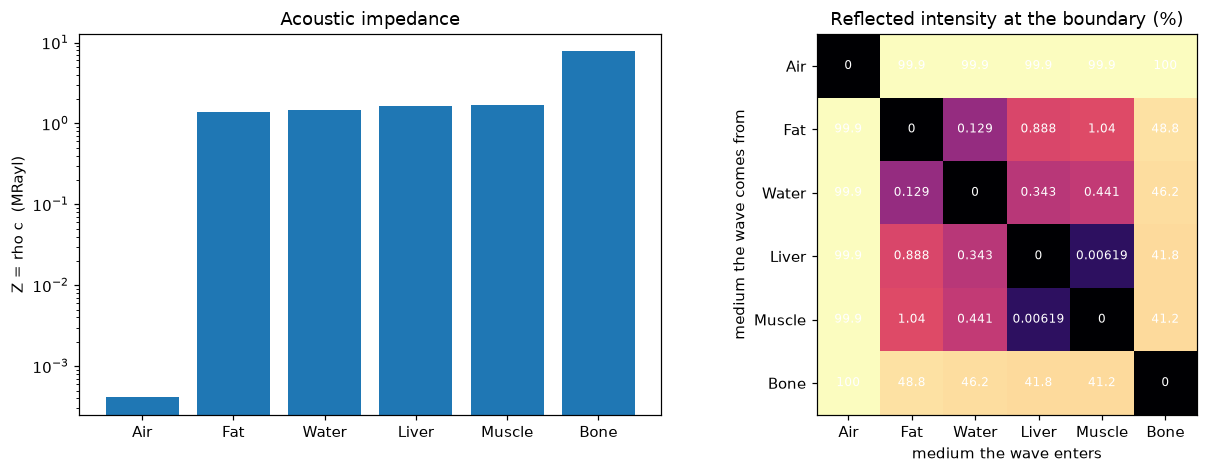

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi, signal

plt.rcParams["figure.dpi"] = 110

# approximate textbook values: (density kg/m^3, speed of sound m/s)
tissues = {"Air": (1.2, 343), "Fat": (950, 1450), "Water": (1000, 1480),
           "Liver": (1060, 1570), "Muscle": (1070, 1580), "Bone": (1900, 4080)}
names = list(tissues)
Zt = np.array([rho * c / 1e6 for rho, c in tissues.values()])       # MRayl
for n, (rho, c), z in zip(names, tissues.values(), Zt):
    print(f"{n:7s} rho={rho:7.1f} kg/m^3   c={c:5d} m/s   Z={z:7.4f} MRayl")

# R[i, j]: wave travelling from medium i into medium j
R = (Zt[None, :] - Zt[:, None]) / (Zt[None, :] + Zt[:, None])
pct = 100 * R ** 2                                                  # reflected intensity, percent

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].bar(names, Zt, color="tab:blue"); ax[0].set_yscale("log")
ax[0].set_ylabel("Z = rho c  (MRayl)"); ax[0].set_title("Acoustic impedance")
im = ax[1].imshow(np.log10(pct + 1e-3), cmap="magma", vmin=-3, vmax=2)
for i in range(len(names)):
    for j in range(len(names)):
        ax[1].text(j, i, f"{pct[i, j]:.3g}", ha="center", va="center", color="w", fontsize=8)
ax[1].set_xticks(range(len(names)), names); ax[1].set_yticks(range(len(names)), names)
ax[1].set_xlabel("medium the wave enters"); ax[1].set_ylabel("medium the wave comes from")
ax[1].set_title("Reflected intensity at the boundary (%)")
plt.tight_layout(); plt.show()

Soft tissues have nearly the same impedance, so a boundary between two of them reflects only a **fraction of a percent
to a few percent** of the intensity. That is good: most of the energy passes through and reaches deeper structures, and
the weak echoes are what make up the image. The extremes are the exceptions:

- **Tissue to air** reflects about 99.9 % of the intensity, which is why gel is used between the probe and the skin and
  why lung and bowel gas block the view.
- **Tissue to bone** reflects roughly 40 % or more, which gives a bright echo and a strong acoustic shadow behind it.

## 2. Beer–Lambert attenuation

As the pulse travels it is absorbed and scattered. Over a distance $z$ the intensity falls exponentially, the
Beer–Lambert law:

$$I(z) = I_0\,e^{-\mu z}, \qquad \text{in decibels: } \; 10\log_{10}\frac{I(z)}{I_0} = -\alpha\, f\, z .$$

In tissue the attenuation coefficient is roughly proportional to frequency, $\alpha \approx 0.5$ dB cm$^{-1}$ MHz$^{-1}$,
and the two forms are related by $\mu = \alpha f \ln 10/10$ per cm. Echoes travel down **and back**, so the
path is $2z$:

$$\text{round-trip loss} = 2\,\alpha\,f\,z \;\text{dB} .$$

Higher frequency gives shorter wavelength, $\lambda = c/f$, and therefore finer axial resolution, but it is attenuated
faster. If the scanner can display about 60 dB of echo dynamic range, the maximum useful depth is roughly
$z_{\max} = 60/(2\alpha f)$.

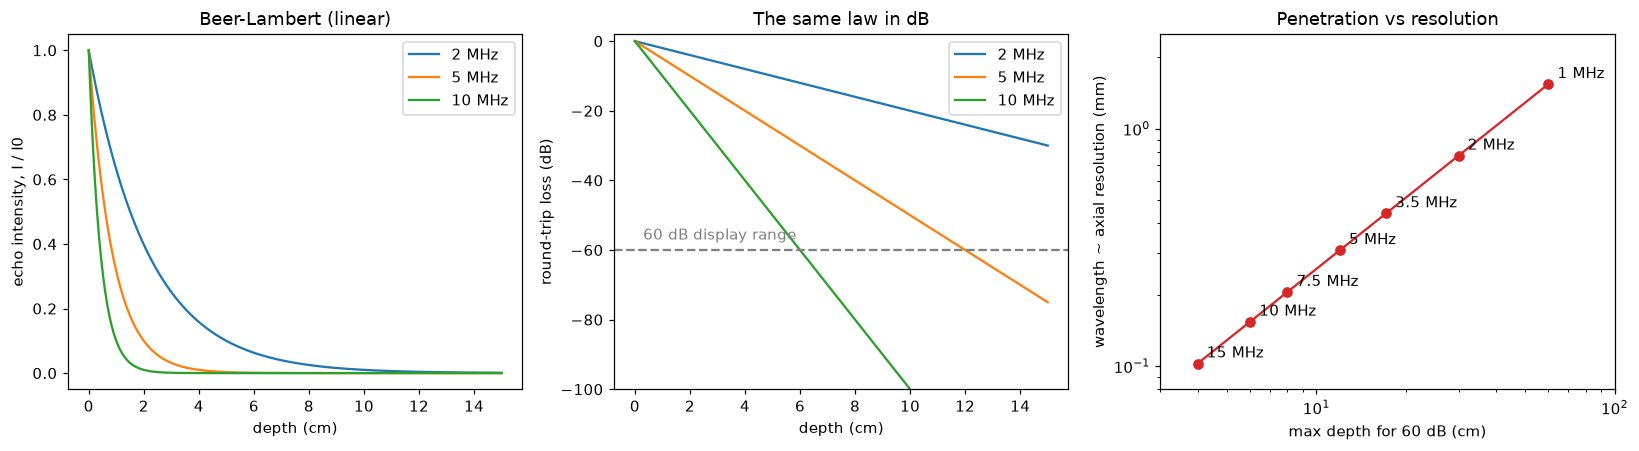

In [2]:
ALPHA = 0.5                        # dB / cm / MHz, soft tissue
z_cm = np.linspace(0, 15, 400)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for f in (2, 5, 10):
    mu_I = ALPHA * f * np.log(10) / 10                      # intensity attenuation, 1/cm
    I_rel = np.exp(-mu_I * 2 * z_cm)                        # Beer-Lambert over the round trip 2z
    assert np.allclose(10 * np.log10(I_rel), -2 * ALPHA * f * z_cm)   # dB form is the same law
    ax[0].plot(z_cm, I_rel, label=f"{f} MHz")
    ax[1].plot(z_cm, 10 * np.log10(I_rel), label=f"{f} MHz")
ax[0].set_xlabel("depth (cm)"); ax[0].set_ylabel("echo intensity, I / I0"); ax[0].set_title("Beer-Lambert (linear)")
ax[1].axhline(-60, ls="--", color="gray"); ax[1].text(0.3, -57, "60 dB display range", color="gray")
ax[1].set_ylim(-100, 2)
ax[1].set_xlabel("depth (cm)"); ax[1].set_ylabel("round-trip loss (dB)"); ax[1].set_title("The same law in dB")
for a in ax[:2]:
    a.legend()

f_axis = np.array([1, 2, 3.5, 5, 7.5, 10, 15])
lam_mm = 1.54 / f_axis                                      # lambda = c / f
pen_cm = 60 / (2 * ALPHA * f_axis)
ax[2].loglog(pen_cm, lam_mm, "o-", color="tab:red")
for fx, px, lx in zip(f_axis, pen_cm, lam_mm):
    ax[2].annotate(f"{fx:g} MHz", (px, lx), textcoords="offset points", xytext=(6, 4))
ax[2].set_xlabel("max depth for 60 dB (cm)"); ax[2].set_ylabel("wavelength ~ axial resolution (mm)")
ax[2].set_title("Penetration vs resolution")
ax[2].set_xlim(3, 100); ax[2].set_ylim(0.08, 2.5)
plt.tight_layout(); plt.show()

## 3. Forming one A-line

An **A-line** (amplitude line) is the echo signal along a single scan line. We build it from the physics above, step
by step, for a medium whose properties vary with depth $z$:

1. impedance $Z(z)=\rho(z)\,c(z)$ gives a **reflection coefficient** $r(z)$ wherever $Z$ changes
   (boundaries) plus small random impedance fluctuations from tissue microstructure (these produce speckle);
2. each echo is weakened by the **round-trip attenuation** $e^{-2\int \mu_A\,dz}$ (Beer–Lambert, amplitude form) and by the
   **two-way interface transmission** $\prod (1-r_i^2)$ of every boundary it crossed;
3. the weighted reflectivity is convolved with the **transmitted pulse** (a short cosine burst at the center frequency
   $f_0$), exactly the $J = I * H$ picture from the previous notebook, with $H$ now the axial pulse;
4. the **envelope** (Hilbert transform magnitude) is taken and **log-compressed** for display.

Time is converted to depth using an assumed speed of sound of 1540 m/s.

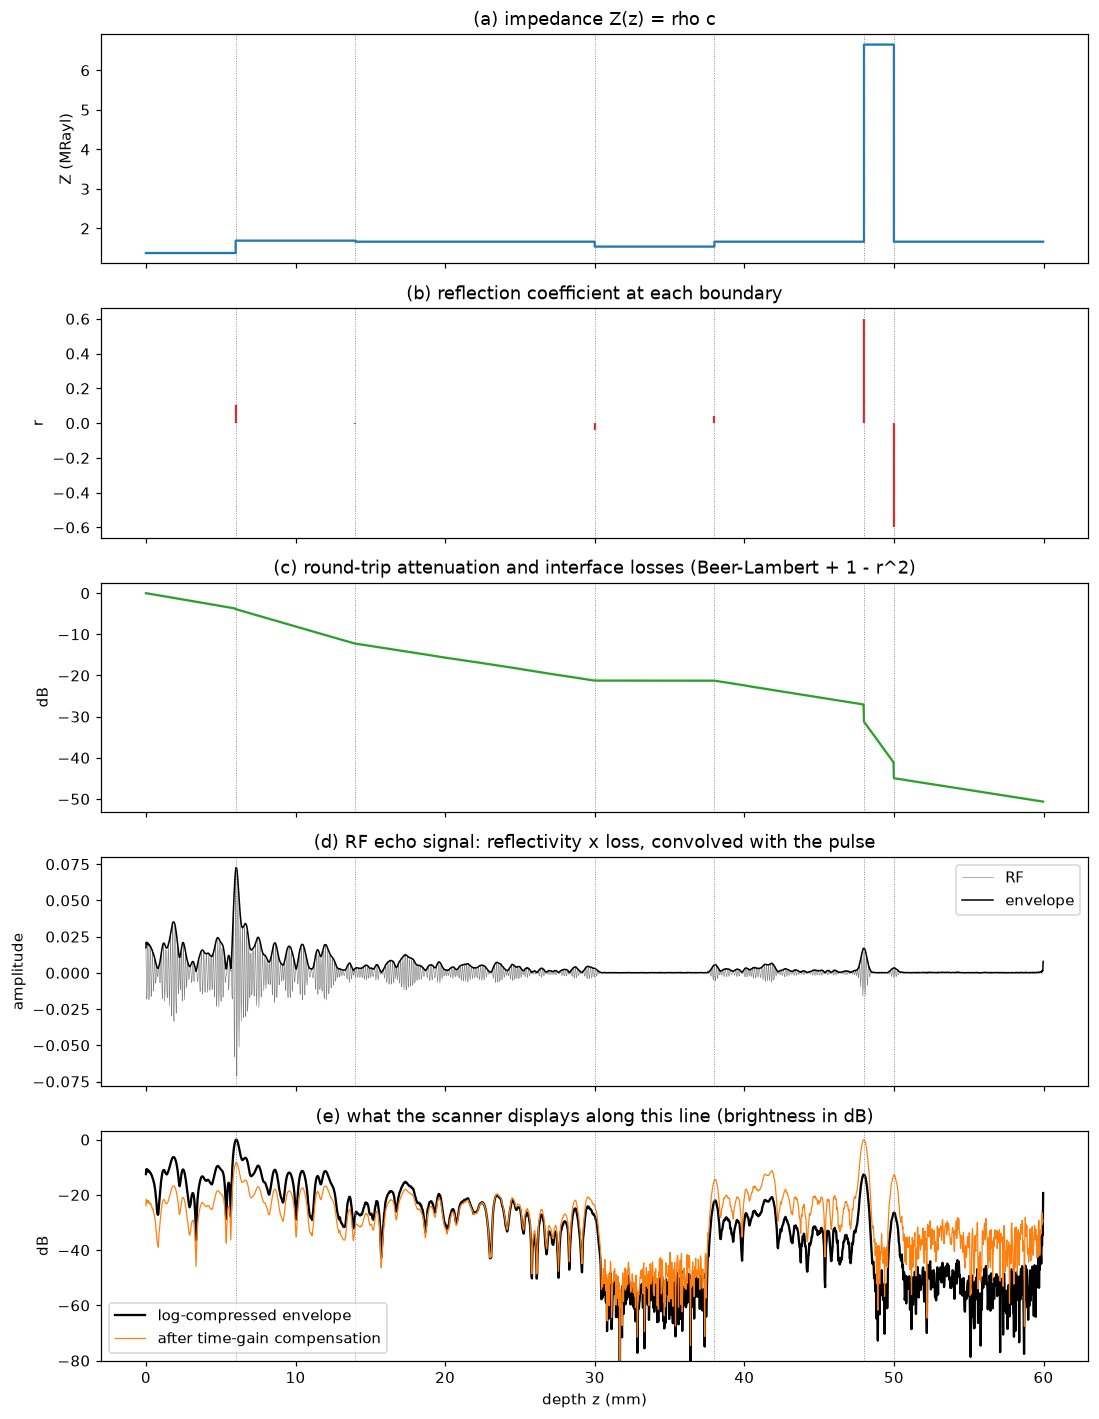

stone (Z=6.65 MRayl) vs liver (Z=1.66): R = 0.60


In [3]:
F0 = 5.0                    # MHz transducer centre frequency
C0 = 1540.0                 # m/s, speed of sound assumed by the scanner
dz = 0.025                  # mm per sample along a scan line
LN10 = np.log(10)

# (density kg/m^3, speed of sound m/s, attenuation dB/cm/MHz, scattering strength)
PROPS = {"liver": (1060, 1570, 0.5, 1.0), "fat": (950, 1450, 0.6, 0.6), "muscle": (1070, 1580, 1.0, 0.8),
         "fluid": (1000, 1540, 0.0, 0.0), "stone": (1900, 3500, 5.0, 0.2)}
LAB = {k: i for i, k in enumerate(PROPS)}
Z_tab = np.array([rho * c / 1e6 for rho, c, a, s in PROPS.values()])      # MRayl
A_tab = np.array([a for rho, c, a, s in PROPS.values()])
S_tab = np.array([s for rho, c, a, s in PROPS.values()])


def pulse(f0, cycles_sigma=1.0):
    # Gaussian-windowed cosine burst in depth (round trip, so spatial period = lambda/2)
    sigma = cycles_sigma / f0                                              # mm
    n = int(round(4 * sigma / dz))
    zz = np.arange(-n, n + 1) * dz * 1e-3                                  # metres
    return np.cos(4 * np.pi * f0 * 1e6 * zz / C0) * np.exp(-0.5 * (zz / (sigma * 1e-3)) ** 2)


def simulate_rf(lab, f0=F0, texture=0.02, sigma_x=0.0, noise=1e-4, seed=0):
    # RF echo signal(s) for a label map whose LAST axis is depth.
    g = np.random.default_rng(seed)
    Z, alpha, scat = Z_tab[lab], A_tab[lab], S_tab[lab]
    Zf = Z * (1 + texture * scat * g.standard_normal(Z.shape))             # microstructure -> speckle
    refl = np.zeros_like(Zf)
    refl[..., 1:] = (Zf[..., 1:] - Zf[..., :-1]) / (Zf[..., 1:] + Zf[..., :-1])    # reflection coefficient
    mu_A = alpha * f0 * LN10 / 200                                         # amplitude attenuation, Np/mm
    loss = np.cumprod(1 - refl ** 2, axis=-1) * np.exp(-2 * np.cumsum(mu_A, axis=-1) * dz)
    echoes = refl * loss
    if sigma_x > 0:
        echoes = ndi.gaussian_filter1d(echoes, sigma_x, axis=0)            # finite lateral beam width
    rf = ndi.convolve1d(echoes, pulse(f0), axis=-1)
    rf = rf + noise * g.standard_normal(rf.shape)                          # electronic noise
    return rf, refl, loss


def tgc(rf, zs_mm, f0, alpha_assumed=0.5, max_gain_db=30):
    # Time-gain compensation: undo the *expected* round-trip loss (scanners cap the gain to limit noise)
    gain_db = np.minimum(2 * alpha_assumed * f0 * zs_mm / 10, max_gain_db)
    return rf * 10 ** (gain_db / 20)


def env_db(rf, ref=None):
    env = np.abs(signal.hilbert(rf, axis=-1))
    ref = env.max() if ref is None else ref
    return env, 20 * np.log10(env / ref + 1e-12)


# --- a layered 1-D medium: fat, muscle, liver with a fluid pocket and a thin stone plate ---
nz = 2400
zs = np.arange(nz) * dz                                  # mm
lab1 = np.full(nz, LAB["liver"])
lab1[zs < 6] = LAB["fat"]
lab1[(zs >= 6) & (zs < 14)] = LAB["muscle"]
lab1[(zs >= 30) & (zs < 38)] = LAB["fluid"]
lab1[(zs >= 48) & (zs < 50)] = LAB["stone"]

rf1, refl_texture, loss1 = simulate_rf(lab1)
Z1 = Z_tab[lab1]
r_clean = np.zeros(nz); r_clean[1:] = (Z1[1:] - Z1[:-1]) / (Z1[1:] + Z1[:-1])
env1, db1 = env_db(rf1)
env1_t, db1_t = env_db(tgc(rf1, zs, F0), ref=None)

edges = zs[np.where(np.diff(lab1) != 0)[0] + 1]
fig, ax = plt.subplots(5, 1, figsize=(10, 13), sharex=True)
ax[0].step(zs, Z1, where="post"); ax[0].set_ylabel("Z (MRayl)"); ax[0].set_title("(a) impedance Z(z) = rho c")
ax[1].vlines(zs[r_clean != 0], 0, r_clean[r_clean != 0], color="tab:red")
ax[1].set_ylabel("r"); ax[1].set_title("(b) reflection coefficient at each boundary")
ax[2].plot(zs, 20 * np.log10(loss1), color="tab:green"); ax[2].set_ylabel("dB")
ax[2].set_title("(c) round-trip attenuation and interface losses (Beer-Lambert + 1 - r^2)")
ax[3].plot(zs, rf1, lw=0.4, color="gray", label="RF"); ax[3].plot(zs, env1, color="k", lw=1, label="envelope")
ax[3].set_ylabel("amplitude"); ax[3].legend(loc="upper right"); ax[3].set_title("(d) RF echo signal: reflectivity x loss, convolved with the pulse")
ax[4].plot(zs, db1, color="k", label="log-compressed envelope")
ax[4].plot(zs, db1_t - db1_t.max(), color="tab:orange", lw=0.8, label="after time-gain compensation")
ax[4].set_ylim(-80, 3); ax[4].set_ylabel("dB"); ax[4].set_xlabel("depth z (mm)"); ax[4].legend(loc="lower left")
ax[4].set_title("(e) what the scanner displays along this line (brightness in dB)")
for a in ax:
    for e in edges:
        a.axvline(e, color="gray", ls=":", lw=0.6)
plt.tight_layout(); plt.show()
print(f"stone (Z={Z_tab[LAB['stone']]:.2f} MRayl) vs liver (Z={Z_tab[LAB['liver']]:.2f}): R = "
      f"{(Z_tab[LAB['stone']] - Z_tab[LAB['liver']]) / (Z_tab[LAB['stone']] + Z_tab[LAB['liver']]):.2f}")

Reading the figure from top to bottom: each **step in $Z$** (a) becomes a **spike in $r$** (b), strongest at the
stone plate. The cumulative loss (c) decays with depth because of Beer–Lambert attenuation, with a steeper drop inside
the stone and extra loss at its two interfaces. The RF signal (d) is the weighted reflectivity convolved with the pulse, and the
log-compressed envelope (e) is what becomes brightness. Fat/muscle/liver boundaries are weak (a few percent in
amplitude), the stone's front face is very bright, and behind the stone the signal is greatly reduced:
the beginning of an **acoustic shadow**. Echoes from the fluid pocket are almost absent because fluid has almost no
internal scatterers (only its two boundaries reflect).

## 4. From lines to an image: a B-mode phantom

A **B-mode** image (brightness mode) is made by repeating the A-line at many lateral positions. We build a
2-D phantom with the same ingredients:

- a fat layer and a muscle layer over liver-like tissue (different $Z$, $\alpha$ and scattering strength);
- a **cyst**: fluid, with almost no attenuation and no internal scatterers;
- a **stone**: high impedance and strongly attenuating.

For each of 160 scan lines we form the RF signal as in Section 3, with a finite lateral beam width blending
neighbouring lines. Then we take the envelope and log-compress.

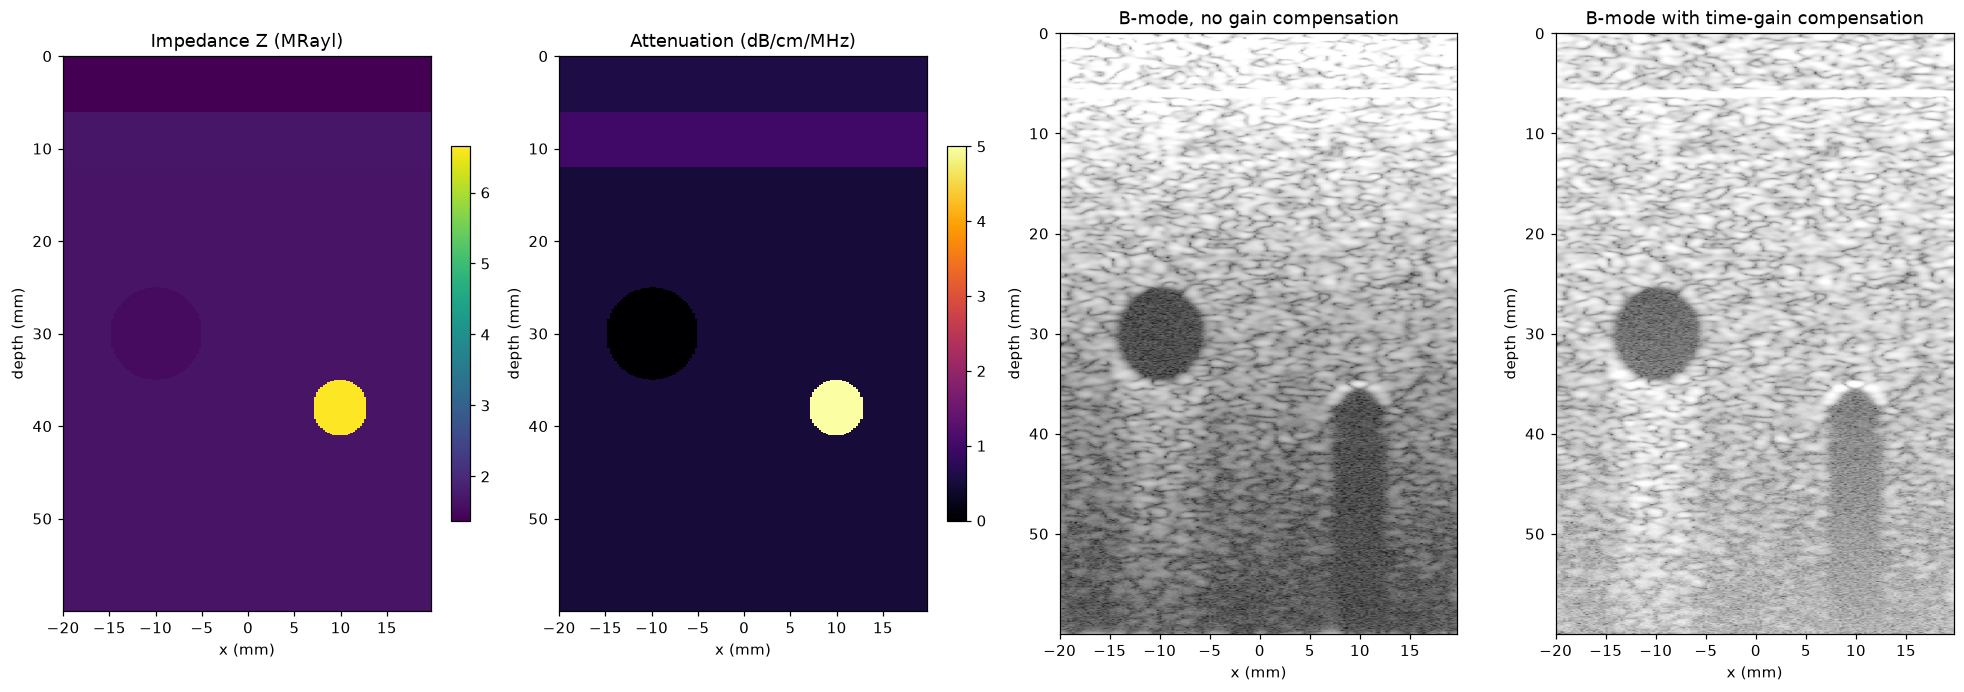

In [4]:
nx, pitch = 160, 0.25                                     # scan lines, mm between lines
xs = (np.arange(nx) - nx / 2) * pitch                     # mm
Xm, Zm = np.meshgrid(xs, zs, indexing="ij")               # (line, depth)

lab2 = np.full((nx, nz), LAB["liver"])
lab2[Zm < 6] = LAB["fat"]
lab2[(Zm >= 6) & (Zm < 12)] = LAB["muscle"]
lab2[np.hypot(Xm + 10, Zm - 30) < 5] = LAB["fluid"]       # cyst, centre (x=-10, z=30), radius 5 mm
lab2[np.hypot(Xm - 10, Zm - 38) < 3] = LAB["stone"]       # stone, centre (x=+10, z=38), radius 3 mm

TEX, SX = 0.04, 2.0
rf2, refl2, loss2 = simulate_rf(lab2, texture=TEX, sigma_x=SX, seed=3)
env2, _ = env_db(rf2)
rf2_t = tgc(rf2, zs[None, :], F0)
env2_t, _ = env_db(rf2_t)
win = slice(int(12 / dz), int(20 / dz))                    # reference window: liver at 12-20 mm
ref_raw, ref_tgc = np.percentile(env2[:, win], 99), np.percentile(env2_t[:, win], 99)
B_raw = 20 * np.log10(env2 / ref_raw + 1e-12)
B_tgc = 20 * np.log10(env2_t / ref_tgc + 1e-12)

EXT = [xs[0], xs[-1], zs[-1], zs[0]]
fig, ax = plt.subplots(1, 4, figsize=(18, 6.2))
im0 = ax[0].imshow(Z_tab[lab2].T, extent=EXT, cmap="viridis", aspect="equal", interpolation="nearest")
ax[0].set_title("Impedance Z (MRayl)"); plt.colorbar(im0, ax=ax[0], fraction=0.046)
im1 = ax[1].imshow(A_tab[lab2].T, extent=EXT, cmap="inferno", aspect="equal", interpolation="nearest")
ax[1].set_title("Attenuation (dB/cm/MHz)"); plt.colorbar(im1, ax=ax[1], fraction=0.046)
ax[2].imshow(B_raw[:, ::2].T, extent=EXT, cmap="gray", vmin=-60, vmax=0, aspect="equal")
ax[2].set_title("B-mode, no gain compensation")
ax[3].imshow(B_tgc[:, ::2].T, extent=EXT, cmap="gray", vmin=-60, vmax=0, aspect="equal")
ax[3].set_title("B-mode with time-gain compensation")
for a in ax:
    a.set_xlabel("x (mm)"); a.set_ylabel("depth (mm)")
plt.tight_layout(); plt.show()

The left two panels are the **ground truth** (what $Z$ and $\alpha$ really are). The right two panels are what the
scanner would show.

- The **cyst** (left, $x=-10$ mm) is dark inside because a fluid has no internal scatterers: its outline is visible only
  through faint boundary echoes.
- The **stone** (right, $x=+10$ mm) has a bright front surface (large $Z$ mismatch) and a dark **acoustic shadow**
  below it: the echoes from behind are attenuated by the stone and by the two interface crossings.
- Without compensation the image fades with depth (Beer–Lambert). After gain compensation the background is uniform.

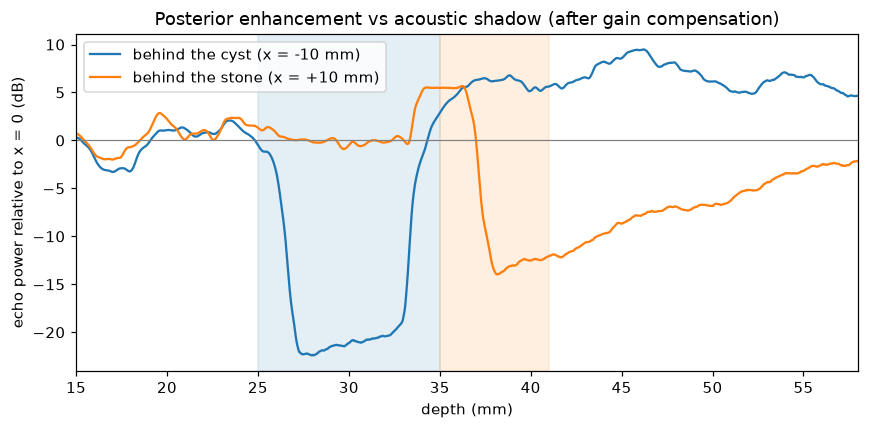

In [5]:
# Compare the signal behind each inclusion with the signal at the same depth in undisturbed liver (x = 0)
def band_power(env, x0, half=2.0):
    m = np.abs(xs - x0) < half
    return ndi.uniform_filter1d((env[m] ** 2).mean(axis=0), size=int(3 / dz))     # smooth over 3 mm

ref_p = band_power(env2_t, 0.0)
rel_cyst = 10 * np.log10(band_power(env2_t, -10.0) / ref_p)
rel_stone = 10 * np.log10(band_power(env2_t, 10.0) / ref_p)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(zs, rel_cyst, label="behind the cyst (x = -10 mm)")
ax.plot(zs, rel_stone, label="behind the stone (x = +10 mm)")
ax.axhline(0, color="gray", lw=0.8)
ax.axvspan(25, 35, color="tab:blue", alpha=0.12); ax.axvspan(35, 41, color="tab:orange", alpha=0.12)
ax.set_xlim(15, 58); ax.set_xlabel("depth (mm)"); ax.set_ylabel("echo power relative to x = 0 (dB)")
ax.set_title("Posterior enhancement vs acoustic shadow (after gain compensation)")
ax.legend(); plt.tight_layout(); plt.show()

Directly behind the cyst the echoes are **stronger** than in neighbouring tissue (**posterior acoustic enhancement**):
the pulse crossed a stretch of almost lossless fluid, so it lost less energy than the pulse in the neighbouring
liver, but the scanner's gain compensation assumed liver-like attenuation everywhere and so over-corrected. Behind the
stone the echoes are **weaker** (**acoustic shadowing**). The shadow does not reach the full depth the
physics would suggest, because the gain that restores deep signals also amplifies the electronic noise.
Both artifacts are direct consequences of Beer–Lambert with a spatially varying $\mu$, and sonographers use them
diagnostically (a fluid-filled cyst enhances, a calculus shadows).

## 5. Frequency: resolution versus penetration

The same phantom imaged at three center frequencies (same tissue, same noise, same gain model).
Because $\alpha \propto f$, doubling the frequency doubles the round-trip loss in dB at a given depth; because
$\lambda \propto 1/f$, it also shortens the pulse and improves axial detail. Gain compensation is capped at 30 dB,
as on a real scanner, so past the depth where the cap is reached the image fades into noise.

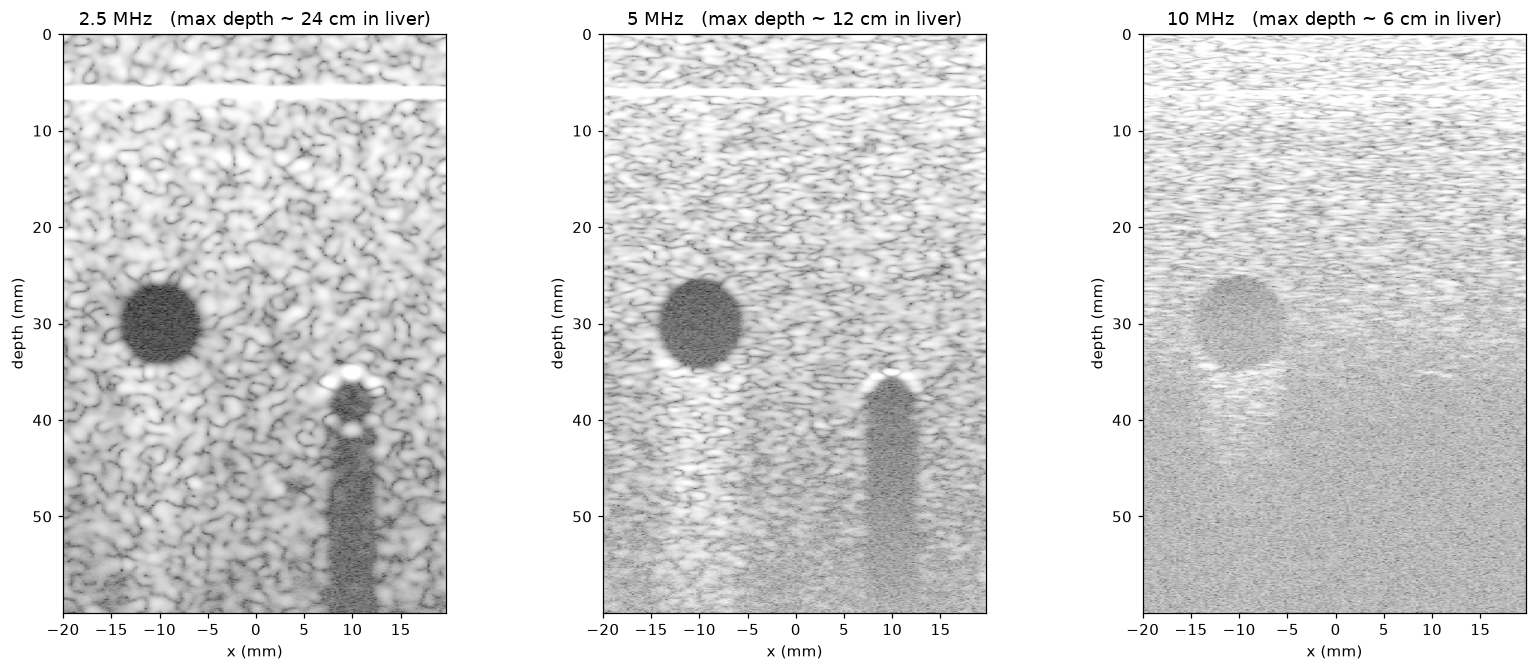

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6.2))
for a, f in zip(ax, (2.5, 5.0, 10.0)):
    rf_f, _, _ = simulate_rf(lab2, f0=f, texture=TEX, sigma_x=SX, seed=3)
    env_f, _ = env_db(tgc(rf_f, zs[None, :], f, alpha_assumed=0.5))
    B = 20 * np.log10(env_f / np.percentile(env_f[:, win], 99) + 1e-12)
    a.imshow(B[:, ::2].T, extent=EXT, cmap="gray", vmin=-60, vmax=0, aspect="equal")
    a.set_title(f"{f:g} MHz   (max depth ~ {60 / (2 * ALPHA * f):.0f} cm in liver)")
    a.set_xlabel("x (mm)"); a.set_ylabel("depth (mm)")
plt.tight_layout(); plt.show()

## Takeaways

- Echoes come from **impedance mismatches**: $R=(Z_2-Z_1)/(Z_2+Z_1)$ with $Z=\rho c$. Soft–soft boundaries reflect
  about 1 % or less of the intensity; tissue–air and tissue–bone boundaries reflect a large fraction.
- The echo arrival time gives depth, $z=ct/2$, and the echo amplitude carries the reflectivity weighted by the
  attenuation the pulse suffered on the way.
- Attenuation follows **Beer–Lambert**, $I=I_0e^{-\mu z}$, equivalently $-\alpha f z$ dB one way and $-2\alpha f z$ dB
  for the echo. Because $\alpha$ grows with frequency, high frequency buys resolution at the cost of penetration.
- A simple image-formation model has four steps: impedance map to reflectivity, multiply by attenuation and
  interface loss, convolve with the pulse ($J=I*H$ along the beam), then envelope and log compression. Stacking lines
  gives a B-mode image.
- Many familiar ultrasound artifacts, including shadowing, posterior enhancement, the need for time-gain
  compensation, and speckle, fall out of this model.

**Try it:** change `ALPHA`, give the cyst a nonzero attenuation, move the stone deeper, raise `noise` in `simulate_rf`,
or set `TEX` to 0 to see boundaries without speckle. The model assumes normal incidence, a single center frequency
and a constant speed of sound for display; real scanners also account for refraction, frequency-dependent
attenuation (the pulse spectrum shifts down with depth) and beam focusing.